# Partición de datos sin fuga y líneas base — Automotive Vehicles Engine Health Dataset

Fase 3 de CRISP-ML(Q) (*Data Preparation* y *Modeling*, primera parte): partición estratificada 70/15/15 con semilla fija y evaluación de las dos líneas base (clasificador de clase predominante y regresión logística) con validación cruzada sobre el conjunto de entrenamiento.

La lógica está en los scripts `src/particion.py` y `src/lineas_base.py`, que se pueden ejecutar desde la terminal. Este notebook los usa y documenta sus resultados.

In [7]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

def raiz_proyecto():
    """Ubica la carpeta raíz del proyecto (la que contiene data/) sin depender de dónde se ejecute el notebook."""
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "data").is_dir() and (carpeta / "src").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la carpeta raíz del proyecto (con data/ y src/).")

RAIZ = raiz_proyecto()
sys.path.insert(0, str(RAIZ / "src"))

from datos import OBJETIVO, SEMILLA, VARIABLES, cargar_datos_originales
from particion import particionar, resumen, verificar_sin_solapamiento
from lineas_base import evaluar_en_validacion, modelos_base, validacion_cruzada

pd.set_option("display.float_format", "{:.4f}".format)

df = cargar_datos_originales()
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (19535, 7)


,rpm,presion_aceite,presion_combustible,presion_refrigerante,temp_aceite,temp_refrigerante,condicion
0,700,2.4936,11.7909,3.1790,84.1442,81.6322,1
1,876,2.9416,16.1939,2.4645,77.6409,82.4457,0
2,520,2.9617,6.5531,1.0643,77.7523,79.6458,1
3,473,3.7078,19.5102,3.7275,74.1299,71.7746,1
4,619,5.6729,15.7389,2.0523,78.3970,87.0002,0


## 1. Partición estratificada 70/15/15

- **Entrenamiento (70 %):** los modelos aprenden con estos datos.
- **Validación (15 %):** se usa para comparar modelos y elegir hiperparámetros.
- **Prueba (15 %):** se reserva intacta hasta la evaluación final (paso 7).

La partición es **estratificada**: cada conjunto conserva la proporción original de 63 % defectuosos y 37 % normales. Se hace en dos cortes (70/30 y luego 30 en 15/15), ambos con semilla 42 para que el resultado sea siempre el mismo.

In [8]:
particiones = particionar(df)
resumen(particiones, len(df))

,particion,registros,porcentaje_del_total,porcentaje_defectuoso
0,entrenamiento,13674,70.0000,63.0500
1,validacion,2930,15.0000,63.0400
2,prueba,2931,15.0000,63.0500


## 2. Verificación de que no hay fuga de información

La fuga de información (*data leakage*) ocurre cuando datos de validación o prueba influyen en el entrenamiento. El modelo parece mejor de lo que es, porque en cierta forma ya «vio» las respuestas. Se controla de tres maneras:

1. **Sin registros compartidos:** ningún motor aparece en dos particiones.
2. **Partición antes de cualquier transformación:** los datos se dividen primero; ningún cálculo (promedios, escalas) usa el conjunto completo.
3. **Escalador dentro de un `Pipeline`:** la estandarización de la regresión logística se ajusta solo con los datos de entrenamiento de cada pliegue.

In [9]:
verificar_sin_solapamiento(particiones)
print("Sin registros compartidos entre particiones.")

entrenamiento = particiones["entrenamiento"]
print("\nEl escalador usará solo estas", len(entrenamiento), "filas de entrenamiento.")

Sin registros compartidos entre particiones.

El escalador usará solo estas 13674 filas de entrenamiento.


## 3. Líneas base

| Línea base | Qué hace | Para qué sirve |
| --- | --- | --- |
| Clase predominante | Siempre predice «defectuoso», la clase más frecuente | Es el piso: cualquier modelo útil debe superarlo |
| Regresión logística | Combina las 6 variables en una frontera lineal y estima la probabilidad de falla | Es la línea base fuerte: los modelos del paso 6 deben superarla |

Se evalúan con **validación cruzada estratificada de 5 pliegues** sobre el conjunto de entrenamiento: se divide en 5 partes, se entrena con 4 y se mide con la restante, rotando 5 veces. La media indica el desempeño esperado y la desviación estándar indica su estabilidad.

In [10]:
X_ent, y_ent = entrenamiento[VARIABLES], entrenamiento[OBJETIVO]
tabla_cv = validacion_cruzada(modelos_base(), X_ent, y_ent)
tabla_cv[["modelo", "f1_macro_media", "f1_macro_desv", "auc_media", "recall_defectuoso_media", "exactitud_media"]]

,modelo,f1_macro_media,f1_macro_desv,auc_media,recall_defectuoso_media,exactitud_media
0,Clase predominante,0.3867,0.0001,0.5000,1.0000,0.6305
1,Regresión logística,0.5760,0.0068,0.6881,0.8749,0.6595


## 4. Resultado en el conjunto de validación

In [11]:
validacion = particiones["validacion"]
X_val, y_val = validacion[VARIABLES], validacion[OBJETIVO]
tabla_val = evaluar_en_validacion(modelos_base(), X_ent, y_ent, X_val, y_val)
tabla_val

,modelo,f1_macro,auc,recall_defectuoso,exactitud
0,Clase predominante,0.3866,0.5000,1.0000,0.6304
1,Regresión logística,0.5787,0.6876,0.8879,0.6655


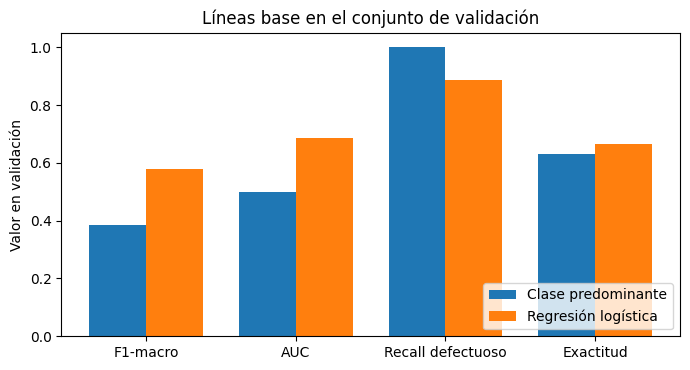

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.8))
metricas = ["f1_macro", "auc", "recall_defectuoso", "exactitud"]
x = range(len(metricas))
ancho = 0.38
for i, (_, fila) in enumerate(tabla_val.iterrows()):
    ax.bar([p + i * ancho for p in x], [fila[m] for m in metricas], width=ancho, label=fila["modelo"])
ax.set_xticks([p + ancho / 2 for p in x])
ax.set_xticklabels(["F1-macro", "AUC", "Recall defectuoso", "Exactitud"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor en validación")
ax.set_title("Líneas base en el conjunto de validación")
ax.legend(loc="lower right")
fig.tight_layout()
(RAIZ / "experiments").mkdir(exist_ok=True)
fig.savefig(RAIZ / "experiments" / "lineas_base_validacion.png", dpi=150)
plt.show()

## 5. Interpretación

1. **El clasificador de clase predominante tiene recall de 1,0 pero F1-macro de 0,39.** Detecta todos los motores defectuosos porque marca todo como defectuoso. Por eso el recall solo no basta y se usa F1-macro como métrica principal.
2. **La regresión logística llega a F1-macro ≈ 0,58 y AUC ≈ 0,69.** Supera claramente al clasificador predominante, con una desviación entre pliegues menor a 0,01 (estable).
3. **La meta para el paso 6:** según la propuesta, el mejor modelo debe alcanzar F1-macro ≥ 0,60 y superar en al menos 0,05 a la mejor línea base, es decir, F1-macro ≥ 0,63 aproximadamente.
4. El conjunto de prueba no se ha usado. Se reserva para la evaluación final.